# Core Technologies 분석

채용공고의 `requirements`, `preferred`, `main_tasks` 컬럼에서 기술 스택을 추출하기 위한 사전 분석.

**목표**
- 어떤 기술 키워드가 자주 등장하는지 파악
- 컬럼별 기술 언급 패턴 차이 확인
- AI 추출 + Label Studio 검수 파이프라인 설계를 위한 기초 데이터 확보

## 1. 데이터 로드

In [45]:
from utils.db import load_job_postings

df = load_job_postings(
    columns=["posting_id", "position", "main_tasks", "requirements", "preferred", "core_technologies", "domain"],
    where="requirements IS NOT NULL"
)
print(f"총 {len(df)}건")
df.head(3)

총 1504건


,posting_id,position,main_tasks,requirements,preferred,core_technologies,domain
0,316484,CAD/Simulation 특화 LLM 파인튜닝 엔지니어,• CAD/Simulation 특화 LLM 모델 파인튜닝• LLM 알고리즘 분석 및...,• AI 모델 개발 및 튜닝 경험자• 코드 생성 LLM 개발 경험자,• AI 관련 학위 소지자 우대해요• 클라우드 플랫폼 경험자 우대해요• 오픈소스 프...,None,None
1,148141,AI R&D 연구원,• 정부 R&D 과제를 위한 머신러닝 모델 설계 및 고도화 - 주어진 Task에 ...,• Python을 활용한 프로젝트 수행 경험이 있으신 분• 딥러닝 프레임워크(Pyt...,,None,None
2,315877,[인턴] [Metheus] AI Research Engineer,"다양한 산업의 기업과 협력하여 현실 세계의 문제와 요구사항을 정의하고, 학문적 수준...",• 업무 진행에 필요한 프로그래밍 언어 및 프레임워크에 익숙하신 분• 현실 세계의 ...,• 오픈소스 컨트리뷰션 경험이 있으신 분• 관련 선행 연구 논문을 조사하고 분석할 ...,None,None


In [46]:
# 컬럼별 데이터 존재 비율
print("컬럼별 비어있지 않은 데이터 비율:")
for col in ["main_tasks", "requirements", "preferred"]:
    non_empty = df[col].notna() & (df[col] != "")
    print(f"  {col}: {non_empty.sum()}/{len(df)} ({non_empty.mean()*100:.1f}%)")

print(f"\n이미 core_technologies가 있는 건수: {df['core_technologies'].notna().sum()}/{len(df)}")

컬럼별 비어있지 않은 데이터 비율:
  main_tasks: 1504/1504 (100.0%)
  requirements: 1504/1504 (100.0%)
  preferred: 1477/1504 (98.2%)

이미 core_technologies가 있는 건수: 0/1504


## 2. 기술 키워드 빈도 분석

채용공고 텍스트에서 기술 스택이 어떤 형태로 등장하는지 파악한다.
- 영문 기술명 (Python, React, Docker 등)은 정규식으로 추출
- 한글 기술 용어 (머신러닝, 딥러닝 등)는 별도 사전으로 매칭

In [47]:
import re
from collections import Counter

# 3개 컬럼 텍스트를 합쳐서 분석
def combine_tech_text(row):
    parts = []
    for col in ["requirements", "preferred", "main_tasks"]:
        if pd.notna(row[col]) and row[col].strip():
            parts.append(row[col])
    return " ".join(parts)

import pandas as pd
df["tech_text"] = df.apply(combine_tech_text, axis=1)

In [48]:
# 알려진 기술 스택 사전 (정규식 패턴 -> 표준명)
TECH_PATTERNS = {
    # ── 프로그래밍 언어 ──
    r"\bPython\b": "Python",
    r"\bJava\b(?!Script)": "Java",
    r"\bJavaScript\b|\bJS\b": "JavaScript",
    r"\bTypeScript\b|\bTS\b": "TypeScript",
    r"\bC\+\+(?=[\s,;.\)·•]|$)|\bCpp\b": "C++",
    r"\bC#(?=[\s,;.\)·•]|$)": "C#",
    r"\bGo\b(?:lang)?\b": "Go",
    r"\bRust\b": "Rust",
    r"\bKotlin\b": "Kotlin",
    r"\bSwift\b": "Swift",
    r"\bScala\b": "Scala",
    r"\bR\b(?=\s|,|\))": "R",
    r"\bSQL\b": "SQL",
    r"\bPHP\b": "PHP",
    r"\bRuby\b": "Ruby",
    r"\bDart\b": "Dart",
    r"\bElixir\b": "Elixir",
    r"\bLua\b": "Lua",
    
    # ── 프론트엔드 ──
    r"\bReact\b(?:\.?js)?": "React",
    r"\bVue\b(?:\.?js)?": "Vue.js",
    r"\bAngular\b": "Angular",
    r"\bNext\.?js\b": "Next.js",
    r"\bNuxt\.?js\b|\bNuxt\b": "Nuxt.js",
    r"\bSvelte\b": "Svelte",
    r"\bHTML\b": "HTML",
    r"\bCSS\b": "CSS",
    r"\bTailwind\b": "Tailwind CSS",
    r"\bReact\s?Native\b": "React Native",
    r"\bFlutter\b": "Flutter",
    r"\bSwiftUI\b": "SwiftUI",
    r"\bJetpack\s?Compose\b": "Jetpack Compose",
    r"\bElectron\b": "Electron",
    r"\bStorybook\b": "Storybook",
    
    # ── 백엔드 ──
    r"\bSpring\b(?:\s?Boot)?": "Spring",
    r"\bDjango\b": "Django",
    r"\bFastAPI\b": "FastAPI",
    r"\bFlask\b": "Flask",
    r"\bNode\.?js\b|\bExpress\b": "Node.js",
    r"\bNest\.?js\b|\bNestJS\b": "NestJS",
    r"\bgRPC\b": "gRPC",
    r"\bGraphQL\b": "GraphQL",
    r"\bREST\s?API\b": "REST API",
    r"\bRabbitMQ\b": "RabbitMQ",
    r"\bCelery\b": "Celery",
    r"\bSupabase\b": "Supabase",
    r"\bPrisma\b": "Prisma",
    
    # ── AI/ML 프레임워크 ──
    r"\bPyTorch\b": "PyTorch",
    r"\bTensorFlow\b|\bTF\b": "TensorFlow",
    r"\bJAX\b": "JAX",
    r"\bScikit[\-\s]?learn\b|\bsklearn\b": "scikit-learn",
    r"\bKeras\b": "Keras",
    r"\bONNX\b": "ONNX",
    r"\bPandas\b": "Pandas",
    r"\bNumPy\b": "NumPy",
    r"\bOpenCV\b": "OpenCV",
    r"\bYOLO\b(?:v\d+)?": "YOLO",
    r"\bTransformer(?:s)?\b": "Transformer",
    r"\bBERT\b": "BERT",
    r"\bDeepSpeed\b": "DeepSpeed",
    r"\bSciPy\b": "SciPy",
    r"\bXGBoost\b": "XGBoost",
    r"\bLightGBM\b": "LightGBM",
    r"\bCatBoost\b": "CatBoost",
    r"\bSPACy\b|\bspaCy\b": "spaCy",
    
    # ── AI Vision / Multimodal ──
    r"\bVLM\b": "VLM",
    r"\bCLIP\b": "CLIP",
    r"\bStable\s?Diffusion\b": "Stable Diffusion",
    r"멀티모달|\bMulti[\-\s]?[Mm]odal\b": "Multimodal",
    r"\bSAM\b(?=.*(?:Segment|segmentation))": "SAM",
    r"\bObject\s?Detection\b|객체\s?탐지|객체\s?검출": "Object Detection",
    
    # ── LLM / AI Agent ──
    r"\bLLM\b": "LLM",
    r"\bRAG\b": "RAG",
    r"\bGPT\b": "GPT",
    r"\bLangChain\b": "LangChain",
    r"\bLangGraph\b": "LangGraph",
    r"\bLangSmith\b": "LangSmith",
    r"\bLlamaIndex\b|\bLlama\s?Index\b": "LlamaIndex",
    r"\bCrewAI\b": "CrewAI",
    r"\bAutoGen\b": "AutoGen",
    r"\bHugging\s?Face\b": "HuggingFace",
    r"\bOpenAI\b": "OpenAI API",
    r"\bClaude\b": "Claude API",
    r"\bGemini\b": "Gemini",
    r"\bLlama\b(?:\s?\d)?": "Llama",
    r"\bMistral\b": "Mistral",
    r"\bWhisper\b": "Whisper",
    r"\bvLLM\b": "vLLM",
    r"\bOllama\b": "Ollama",
    r"\bLoRA\b|\bQLoRA\b": "LoRA",
    r"\bPEFT\b": "PEFT",
    r"\b(?:파인\s?튜닝|Fine[\-\s]?tun(?:e|ing))\b": "Fine-tuning",
    r"\bPrompt\s?Engineer(?:ing)?\b|프롬프트\s?엔지니어링": "Prompt Engineering",
    r"\bAI\s?Agent\b|AI\s?에이전트": "AI Agent",
    r"\bMCP\b(?=.*(?:Model|Context|Protocol))": "MCP",
    r"\bFunction\s?Call(?:ing)?\b": "Function Calling",
    
    # ── Vector DB / 검색 ──
    r"\bVector\s?DB\b|벡터\s?DB|벡터\s?데이터베이스": "Vector DB",
    r"\bPinecone\b": "Pinecone",
    r"\bChroma(?:DB)?\b": "ChromaDB",
    r"\bWeaviate\b": "Weaviate",
    r"\bMilvus\b": "Milvus",
    r"\bQdrant\b": "Qdrant",
    r"\bFAISS\b": "FAISS",
    r"\bpgvector\b": "pgvector",
    
    # ── MLOps / 실험 관리 ──
    r"\bMLOps\b|\bML\s?Ops\b": "MLOps",
    r"\bMLflow\b": "MLflow",
    r"\bKubeflow\b": "Kubeflow",
    r"\bW&B\b|\bWandB\b|\bWeights\s?(?:&|and)\s?Biases\b": "Weights & Biases",
    r"\bDVC\b": "DVC",
    r"\bTriton\b": "Triton",
    r"\bBentoML\b": "BentoML",
    r"\bTensorRT\b": "TensorRT",
    r"\bStreamlit\b": "Streamlit",
    r"\bGradio\b": "Gradio",
    
    # ── 데이터 엔지니어링 ──
    r"\bSpark\b": "Spark",
    r"\bHadoop\b": "Hadoop",
    r"\bAirflow\b": "Airflow",
    r"\bKafka\b": "Kafka",
    r"\bFlink\b": "Flink",
    r"\bdbt\b": "dbt",
    r"\bSnowflake\b": "Snowflake",
    r"\bBigQuery\b": "BigQuery",
    r"\bDatabricks\b": "Databricks",
    r"\bDelta\s?Lake\b": "Delta Lake",
    r"\bPolars\b": "Polars",
    r"\bDuckDB\b": "DuckDB",
    r"\bTrino\b|\bPresto\b": "Trino",
    r"\bPrefect\b": "Prefect",
    r"\bDagster\b": "Dagster",
    
    # ── DB ──
    r"\bMySQL\b": "MySQL",
    r"\bPostgreSQL\b|\bPostgres\b": "PostgreSQL",
    r"\bMongoDB\b|\bMongo\b": "MongoDB",
    r"\bRedis\b": "Redis",
    r"\bElasticsearch\b|\bElastic\b": "Elasticsearch",
    r"\bDynamoDB\b": "DynamoDB",
    r"\bOracle\b": "Oracle",
    r"\bNeo4j\b": "Neo4j",
    r"\bCassandra\b": "Cassandra",
    r"\bClickHouse\b": "ClickHouse",
    r"\bCockroachDB\b": "CockroachDB",
    
    # ── 인프라 / DevOps ──
    r"\bDocker\b": "Docker",
    r"\bKubernetes\b|\bK8s\b": "Kubernetes",
    r"\bAWS\b": "AWS",
    r"\bGCP\b": "GCP",
    r"\bAzure\b": "Azure",
    r"\bTerraform\b": "Terraform",
    r"\bCI\s?/?\s?CD\b": "CI/CD",
    r"\bJenkins\b": "Jenkins",
    r"\bGitHub\s?Actions\b": "GitHub Actions",
    r"\bArgo\s?CD\b|\bArgoCD\b": "ArgoCD",
    r"\bLinux\b": "Linux",
    r"\bNginx\b": "Nginx",
    r"\bGit\b(?!Hub|Lab)": "Git",
    r"\bGrafana\b": "Grafana",
    r"\bPrometheus\b": "Prometheus",
    r"\bDatadog\b": "Datadog",
    r"\bAnsible\b": "Ansible",
    r"\bHelm\b": "Helm",
    r"\bIstio\b": "Istio",
    r"\bOpenTelemetry\b|\bOTel\b": "OpenTelemetry",
    r"\bSentry\b": "Sentry",
    r"\bELK\b": "ELK Stack",
    r"\bPulumi\b": "Pulumi",
    r"\bServerless\b": "Serverless",
    
    # ── 테스팅 ──
    r"\bSelenium\b": "Selenium",
    r"\bPlaywright\b": "Playwright",
    r"\bJest\b": "Jest",
    r"\bCypress\b": "Cypress",
    
    # ── 한글 기술 용어 ──
    r"머신러닝|머신 러닝": "머신러닝",
    r"딥러닝|딥 러닝": "딥러닝",
    r"자연어\s?처리|\bNLP\b": "NLP",
    r"컴퓨터\s?비전|\bCV\b": "컴퓨터비전",
    r"데이터\s?엔지니어링": "데이터엔지니어링",
    r"추천\s?시스템": "추천시스템",
    r"생성\s?AI|생성형\s?AI|\bGenAI\b|\bGenerative\s?AI\b": "생성형 AI",
    r"강화\s?학습|\bRL\b|\bReinforcement\s?Learning\b": "강화학습",
    r"시계열|Time[\-\s]?Series": "시계열",
    r"이상\s?탐지|Anomaly\s?Detection": "이상탐지",
}

print(f"기술 사전: {len(TECH_PATTERNS)}개 패턴")

기술 사전: 177개 패턴


In [49]:
def extract_techs(text: str) -> list[str]:
    """텍스트에서 기술 스택 추출 (중복 제거, 순서 유지)"""
    if not text or not isinstance(text, str):
        return []
    found = []
    seen = set()
    for pattern, name in TECH_PATTERNS.items():
        if re.search(pattern, text, re.IGNORECASE) and name not in seen:
            found.append(name)
            seen.add(name)
    return found

# 전체 공고에 대해 추출
df["extracted_techs"] = df["tech_text"].apply(extract_techs)
df["tech_count"] = df["extracted_techs"].apply(len)

print(f"기술 스택이 1개 이상 추출된 공고: {(df['tech_count'] > 0).sum()}/{len(df)}")
print(f"공고당 평균 기술 수: {df['tech_count'].mean():.1f}개")
print(f"공고당 최대 기술 수: {df['tech_count'].max()}개")

기술 스택이 1개 이상 추출된 공고: 1438/1504
공고당 평균 기술 수: 7.4개
공고당 최대 기술 수: 41개


In [50]:
# 전체 기술 스택 빈도 TOP 30
all_techs = [tech for techs in df["extracted_techs"] for tech in techs]
tech_counts = Counter(all_techs)

print(f"총 {len(tech_counts)}종의 기술 스택 감지\n")
print("=== 기술 스택 빈도 TOP 30 ===")
for tech, count in tech_counts.most_common(50):
    pct = count / len(df) * 100
    bar = "█" * int(pct / 2)
    print(f"  {tech:20s} {count:4d} ({pct:5.1f}%) {bar}")

총 174종의 기술 스택 감지

=== 기술 스택 빈도 TOP 30 ===
  Python                719 ( 47.8%) ███████████████████████
  AWS                   548 ( 36.4%) ██████████████████
  LLM                   355 ( 23.6%) ███████████
  Java                  336 ( 22.3%) ███████████
  Docker                336 ( 22.3%) ███████████
  Kubernetes            313 ( 20.8%) ██████████
  Spring                266 ( 17.7%) ████████
  CI/CD                 239 ( 15.9%) ███████
  Git                   230 ( 15.3%) ███████
  GCP                   225 ( 15.0%) ███████
  JavaScript            224 ( 14.9%) ███████
  PyTorch               213 ( 14.2%) ███████
  SQL                   206 ( 13.7%) ██████
  MySQL                 205 ( 13.6%) ██████
  PostgreSQL            192 ( 12.8%) ██████
  Redis                 192 ( 12.8%) ██████
  딥러닝                   178 ( 11.8%) █████
  RAG                   176 ( 11.7%) █████
  머신러닝                  175 ( 11.6%) █████
  Kafka                 175 ( 11.6%) █████
  Linux                 170

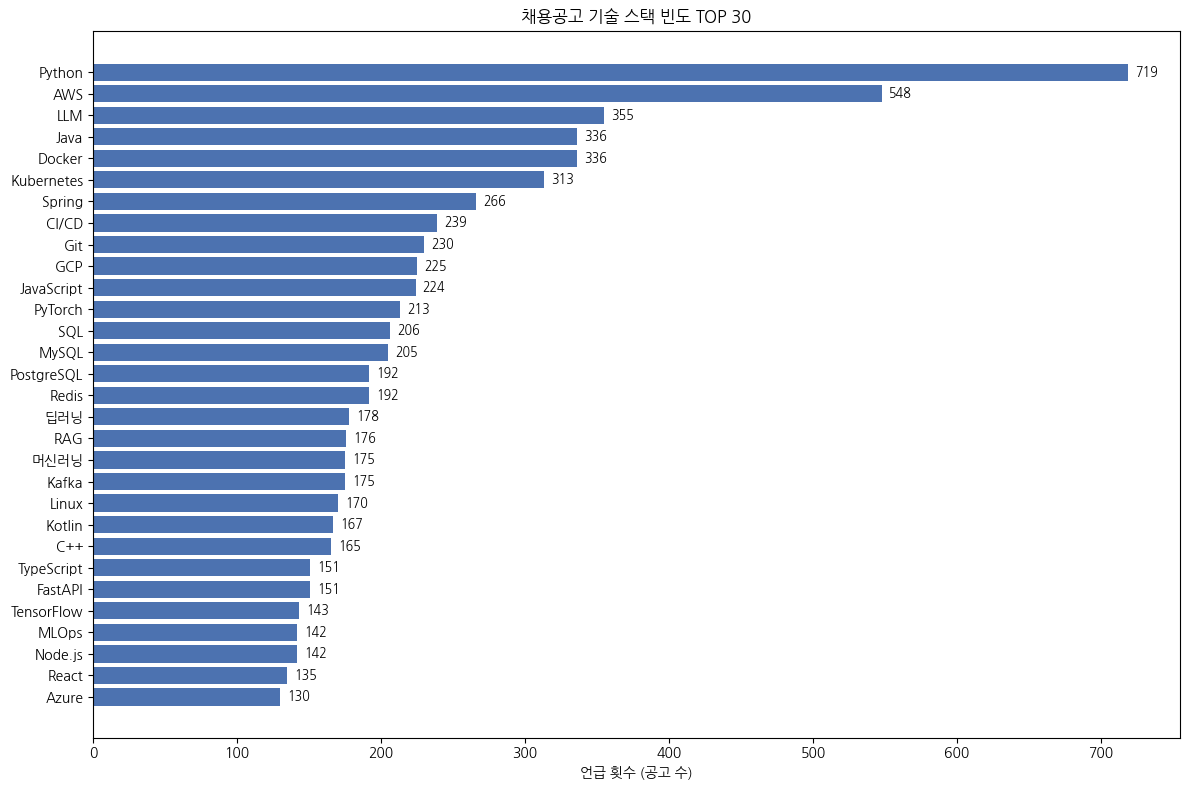

In [51]:
import koreanize_matplotlib
import matplotlib.pyplot as plt

# 시각화
top_30 = tech_counts.most_common(30)
techs, counts = zip(*top_30)

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(range(len(techs)), counts, color="#4C72B0")
ax.set_yticks(range(len(techs)))
ax.set_yticklabels(techs)
ax.invert_yaxis()
ax.set_xlabel("언급 횟수 (공고 수)")
ax.set_title("채용공고 기술 스택 빈도 TOP 30")

for bar, count in zip(bars, counts):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2, 
            str(count), va="center", fontsize=9)

plt.tight_layout()
plt.show()

## 3. 컬럼별 기술 언급 비교

`requirements` (자격요건), `preferred` (우대사항), `main_tasks` (주요업무) 각각에서 어떤 기술이 더 자주 나오는지 비교한다.

In [52]:
# 컬럼별 기술 추출
col_tech_counts = {}
for col in ["requirements", "preferred", "main_tasks"]:
    techs = [tech for text in df[col].dropna() for tech in extract_techs(text)]
    col_tech_counts[col] = Counter(techs)

# TOP 15를 컬럼별로 비교
top_techs = [t for t, _ in tech_counts.most_common(15)]

comparison = pd.DataFrame({
    col: {tech: col_tech_counts[col].get(tech, 0) for tech in top_techs}
    for col in ["requirements", "preferred", "main_tasks"]
})
comparison.columns = ["자격요건", "우대사항", "주요업무"]
comparison

,자격요건,우대사항,주요업무
Python,580,136,117
AWS,216,303,185
LLM,179,206,222
Java,270,54,76
Docker,143,160,79
Kubernetes,106,193,94
Spring,211,45,88
CI/CD,72,118,95
Git,160,43,35
GCP,90,126,35


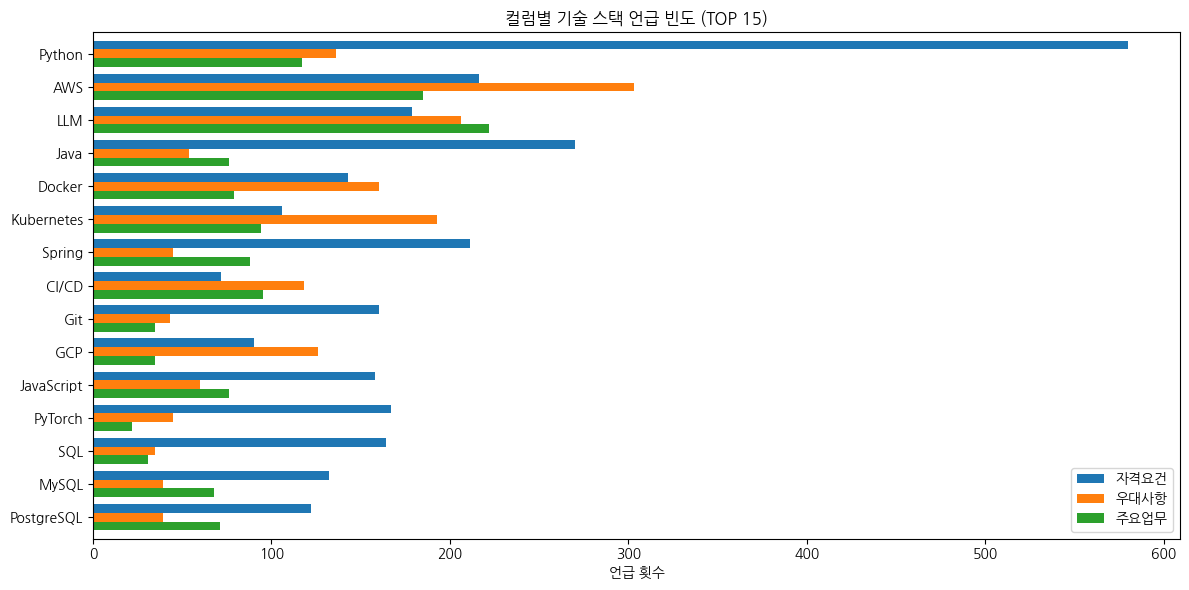

In [53]:
fig, ax = plt.subplots(figsize=(12, 6))
comparison.plot(kind="barh", ax=ax, width=0.8)
ax.invert_yaxis()
ax.set_xlabel("언급 횟수")
ax.set_title("컬럼별 기술 스택 언급 빈도 (TOP 15)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. 도메인별 기술 스택 분포

도메인이 이미 라벨링된 데이터를 활용하여 도메인별로 어떤 기술이 많이 요구되는지 확인한다.

In [54]:
# 도메인별 상위 기술
df_with_domain = df[df["domain"].notna() & (df["tech_count"] > 0)].copy()

if len(df_with_domain) > 0:
    domain_techs = {}
    for domain, group in df_with_domain.groupby("domain"):
        techs = [t for ts in group["extracted_techs"] for t in ts]
        domain_techs[domain] = Counter(techs).most_common(5)

    print(f"도메인별 TOP 5 기술 스택 (도메인 라벨링된 {len(df_with_domain)}건 기준)\n")
    for domain, top5 in sorted(domain_techs.items(), key=lambda x: -len(x[1])):
        techs_str = ", ".join(f"{t}({c})" for t, c in top5)
        print(f"  {domain:20s} → {techs_str}")
else:
    print("도메인 라벨링된 데이터가 없습니다. 도메인 라벨링 후 다시 실행하세요.")

도메인 라벨링된 데이터가 없습니다. 도메인 라벨링 후 다시 실행하세요.


## 5. 정규식 기반 추출의 한계 확인

사전 기반 매칭으로 놓치는 기술이 있는지 확인한다.
추출 결과가 0개인 공고의 텍스트를 샘플링하여 누락 패턴을 파악한다.

In [55]:
# 기술 0개 추출된 공고 샘플
zero_tech = df[df["tech_count"] == 0]
print(f"기술 스택 0개 추출: {len(zero_tech)}건 ({len(zero_tech)/len(df)*100:.1f}%)\n")

if len(zero_tech) > 0:
    print("--- 샘플 (requirements 기준) ---")
    for _, row in zero_tech.sample(min(5, len(zero_tech)), random_state=42).iterrows():
        print(f"\n[{row['posting_id']}] {row['position']}")
        req = row["requirements"]
        if pd.notna(req):
            print(f"  {req[:200]}...")

기술 스택 0개 추출: 66건 (4.4%)

--- 샘플 (requirements 기준) ---

[339012] [하나금융그룹 자회사]Back-end 서버개발
  • 서버 개발 경력 5년 이상• 전산 관련 전공 또는 이에 준하는 실무 경험/역량 보유• 핀테크/금융 서비스 운영·개발 경험자• 정산 업무 설개 개발 운영 경험자• 데이터 수집/분석 관련 시스템 운영 및 개발 경험자...

[328130] 개인화 데이터플랫폼 백엔드 개발자(시니어)
  • JVM 내부 동작 원리 및 가비지 컬렉션(GC) 튜닝을 포함한 애플리케이션 성능 최적화 경험이 있으신 분을 원해요.• OOP를 넘어 함수형 프로그래밍(FP) 개념을 활용하여 데이터 가공 효율성을 높인 경험이 있으신 분을 원해요.• MSA 환경에서 이벤트 기반 통신 및 분산 시스템 디자인 패턴(서킷 브레이커, 리트라이 등) 적용 경험이 있으신 분을 원해요...

[315877] [인턴] [Metheus] AI Research Engineer
  • 업무 진행에 필요한 프로그래밍 언어 및 프레임워크에 익숙하신 분• 현실 세계의 문제를 기술적으로 해결하고자 하는 열정을 가지신 분• 협업을 위한 열린 자세와 논리적인 의사소통 능력을 갖추신 분...

[334775] [프리랜서][거제시]필리핀조선소 SAP ERP 구축 / FCM(FI)개발
  FCM(FI) 프로세스 설계 및 기능 개발조선업 특화 생산 관리 및 프로젝트 관리 모듈 최적화...

[307163] 유동화학(흐름화학) 합성 자동화 연구원(석사이상)
  • 화학/화공 유동화학 관련 박사학위 또는 석사학위 + 4년 이상 경력• Flow 방식의 합성 자동화 연구 경력• 저분자 화합물 빛 반응경로 설계/분석 능력• 유창한 영어실력• 을 미충족할 경우 훌륭한 동기와 실력• Native-level Korean proficiency (for non-Korean applicants)...


In [56]:
# 사전에 없는 영문 기술명 후보 추출 (대문자 시작 단어 중 빈도 높은 것)
known_names = set(TECH_PATTERNS.values())

unknown_candidates = Counter()
for text in df["tech_text"]:
    if not isinstance(text, str):
        continue
    # 대문자로 시작하는 영단어 또는 약어 추출
    tokens = re.findall(r"\b[A-Z][A-Za-z0-9.+#]*(?:\s?[A-Z][A-Za-z0-9.+#]*)*\b", text)
    for token in tokens:
        token = token.strip()
        if token not in known_names and len(token) >= 2 and token not in {"The", "IT", "AI", "ML", "PM", "QA"}:
            unknown_candidates[token] += 1

print("=== 사전에 없는 영문 기술명 후보 (빈도 >= 10) ===\n")
for word, count in unknown_candidates.most_common(40):
    if count >= 10:
        print(f"  {word:30s} {count:4d}")

=== 사전에 없는 영문 기술명 후보 (빈도 >= 10) ===

  API                             552
  CI                              313
  CD                              305
  DB                              224
  Spring Boot                     153
  RDBMS                           153
  RESTful API                     149
  End                             135
  MSA                             131
  NoSQL                           127
  Agent                           126
  GPU                             120
  DevOps                          108
  Backend                         106
  UI                              104
  ETL                              88
  Data                             85
  Multi                            81
  SaaS                             81
  Typescript                       76
  JPA                              74
  S3                               72
  Vision                           67
  On                               65
  ECS                              64
  Slack      

## 6. 기존 core_technologies와 비교

이미 추출된 18건의 `core_technologies` 데이터와 정규식 추출 결과를 비교하여 차이를 확인한다.

In [57]:
# 기존 core_technologies가 있는 데이터와 비교
df_existing = df[df["core_technologies"].notna()].copy()

if len(df_existing) > 0:
    print(f"기존 core_technologies 보유: {len(df_existing)}건\n")
    for _, row in df_existing.iterrows():
        existing = row["core_technologies"] if isinstance(row["core_technologies"], list) else []
        extracted = set(row["extracted_techs"])
        existing_set = set(existing)
        
        only_existing = existing_set - extracted
        only_regex = extracted - existing_set
        
        print(f"[{row['posting_id']}] {row['position'][:40]}")
        print(f"  기존:     {existing}")
        print(f"  정규식:   {row['extracted_techs']}")
        if only_existing:
            print(f"  기존에만:  {only_existing}")
        if only_regex:
            print(f"  정규식에만: {only_regex}")
        print()
else:
    print("기존 core_technologies 데이터 없음")

기존 core_technologies 데이터 없음


## 7. 공고당 기술 수 분포

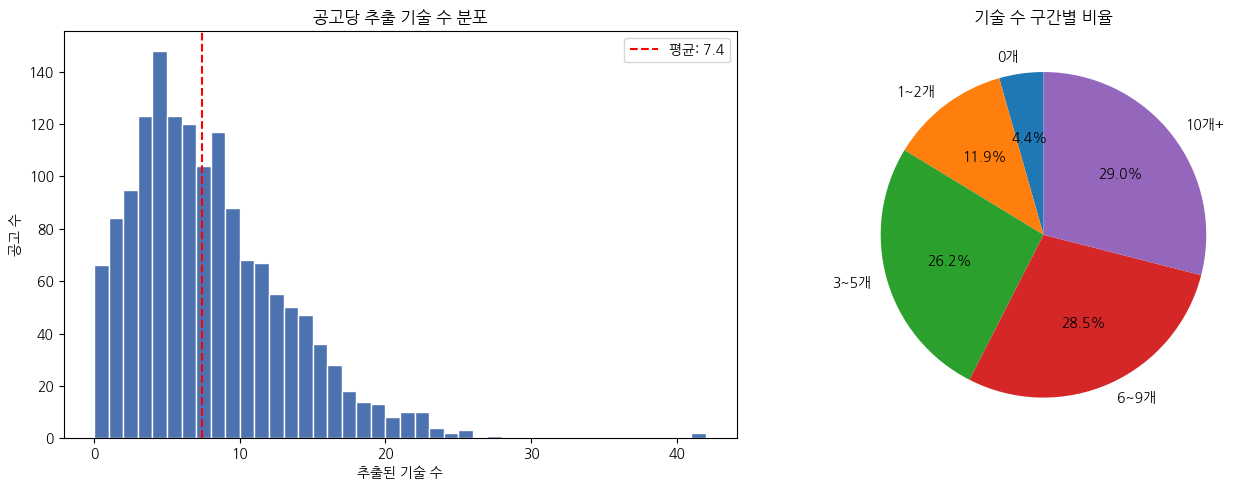


구간별 공고 수:
  0개    : 66건
  1~2개  : 179건
  3~5개  : 394건
  6~9개  : 429건
  10개+  : 436건


In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 히스토그램
axes[0].hist(df["tech_count"], bins=range(0, df["tech_count"].max() + 2), 
             edgecolor="white", color="#4C72B0")
axes[0].set_xlabel("추출된 기술 수")
axes[0].set_ylabel("공고 수")
axes[0].set_title("공고당 추출 기술 수 분포")
axes[0].axvline(df["tech_count"].mean(), color="red", linestyle="--", label=f"평균: {df['tech_count'].mean():.1f}")
axes[0].legend()

# 구간별 비율
bins = [0, 1, 3, 6, 10, 100]
labels = ["0개", "1~2개", "3~5개", "6~9개", "10개+"]
df["tech_bin"] = pd.cut(df["tech_count"], bins=bins, labels=labels, right=False)
bin_counts = df["tech_bin"].value_counts().reindex(labels)
axes[1].pie(bin_counts, labels=labels, autopct="%1.1f%%", startangle=90)
axes[1].set_title("기술 수 구간별 비율")

plt.tight_layout()
plt.show()

print("\n구간별 공고 수:")
for label, count in bin_counts.items():
    print(f"  {label:6s}: {count}건")

## 8. 결론 및 다음 단계

**정규식 기반 추출의 한계:**
- 사전에 등록된 기술만 추출 가능 → 새로운 기술명, 약어, 오타를 놓침
- "데이터 분석", "백엔드 개발" 같은 추상적 역할은 추출 대상이 아님
- 기술의 숙련도/맥락 구분 불가 (필수 vs 우대)

**AI(Claude) 추출이 필요한 이유:**
- 자연어 맥락을 이해하여 기술 스택을 더 정확하게 추출
- 사전에 없는 기술도 감지 가능
- requirements/preferred 구분하여 필수/우대 태깅 가능

**다음 단계:**
1. Claude API로 기술 스택 추출 (requirements + preferred + main_tasks 입력)
2. Label Studio에서 추출 결과 검수 (다중 태그 UI)
3. 검수 완료 데이터를 `core_technologies` (JSONB)에 반영

## 9. 추출 결과 내보내기

정규식 기반 추출 결과를 CSV로 저장하여 Label Studio import에 활용한다.
- `core_tech_result.csv`: posting_id별 추출된 기술 스택 (JSON 배열)
- `prepare_import_data.py`에서 이 파일을 읽어 pre-annotation으로 변환

In [ ]:
import json
from pathlib import Path

OUTPUT_DIR = Path("..") / "labeling_data"

# 기술 스택 → 카테고리 매핑 (Label Studio Taxonomy용)
TECH_CATEGORY = {}
_categories = {
    "프로그래밍 언어": ["Python", "Java", "JavaScript", "TypeScript", "C++", "C#", "Go", "Rust",
                   "Kotlin", "Swift", "Scala", "R", "SQL", "PHP", "Ruby", "Dart", "Elixir", "Lua"],
    "프론트엔드": ["React", "Vue.js", "Angular", "Next.js", "Nuxt.js", "Svelte", "HTML", "CSS",
               "Tailwind CSS", "React Native", "Flutter", "SwiftUI", "Jetpack Compose", "Electron", "Storybook"],
    "백엔드": ["Spring", "Django", "FastAPI", "Flask", "Node.js", "NestJS", "gRPC", "GraphQL",
            "REST API", "RabbitMQ", "Celery", "Supabase", "Prisma"],
    "AI/ML": ["PyTorch", "TensorFlow", "JAX", "scikit-learn", "Keras", "ONNX", "Pandas", "NumPy",
             "OpenCV", "YOLO", "Transformer", "BERT", "DeepSpeed", "SciPy", "XGBoost", "LightGBM",
             "CatBoost", "spaCy", "머신러닝", "딥러닝", "NLP", "컴퓨터비전", "강화학습", "시계열", "이상탐지", "추천시스템"],
    "Vision/Multimodal": ["VLM", "CLIP", "Stable Diffusion", "Multimodal", "SAM", "Object Detection"],
    "LLM/AI Agent": ["LLM", "RAG", "GPT", "LangChain", "LangGraph", "LangSmith", "LlamaIndex",
                     "CrewAI", "AutoGen", "HuggingFace", "OpenAI API", "Claude API", "Gemini",
                     "Llama", "Mistral", "Whisper", "vLLM", "Ollama", "LoRA", "PEFT",
                     "Fine-tuning", "Prompt Engineering", "AI Agent", "MCP", "Function Calling", "생성형 AI"],
    "Vector DB": ["Vector DB", "Pinecone", "ChromaDB", "Weaviate", "Milvus", "Qdrant", "FAISS", "pgvector"],
    "MLOps": ["MLOps", "MLflow", "Kubeflow", "Weights & Biases", "DVC", "Triton", "BentoML",
             "TensorRT", "Streamlit", "Gradio"],
    "데이터 엔지니어링": ["Spark", "Hadoop", "Airflow", "Kafka", "Flink", "dbt", "Snowflake",
                    "BigQuery", "Databricks", "Delta Lake", "Polars", "DuckDB", "Trino", "Prefect",
                    "Dagster", "데이터엔지니어링"],
    "DB": ["MySQL", "PostgreSQL", "MongoDB", "Redis", "Elasticsearch", "DynamoDB", "Oracle",
           "Neo4j", "Cassandra", "ClickHouse", "CockroachDB"],
    "인프라/DevOps": ["Docker", "Kubernetes", "AWS", "GCP", "Azure", "Terraform", "CI/CD",
                    "Jenkins", "GitHub Actions", "ArgoCD", "Linux", "Nginx", "Git", "Grafana",
                    "Prometheus", "Datadog", "Ansible", "Helm", "Istio", "OpenTelemetry",
                    "Sentry", "ELK Stack", "Pulumi", "Serverless"],
    "테스팅": ["Selenium", "Playwright", "Jest", "Cypress"],
}
for cat, techs in _categories.items():
    for tech in techs:
        TECH_CATEGORY[tech] = cat

# CSV 저장: 기술스택 + 원본 텍스트 컬럼 (Label Studio에서 상세 표시용)
export_cols = ["posting_id", "position", "main_tasks", "requirements", "preferred", "extracted_techs", "tech_count"]
export_df = df[export_cols].copy()

# 빈 값 처리
for col in ["main_tasks", "requirements", "preferred"]:
    export_df[col] = export_df[col].fillna("")

export_df["core_technologies"] = export_df["extracted_techs"].apply(json.dumps, ensure_ascii=False)
export_df["tech_categories"] = export_df["extracted_techs"].apply(
    lambda techs: json.dumps(
        [[TECH_CATEGORY.get(t, "기타"), t] for t in techs],
        ensure_ascii=False,
    )
)

output_path = OUTPUT_DIR / "core_tech_result.csv"
export_df[["posting_id", "position", "main_tasks", "requirements", "preferred",
           "core_technologies", "tech_categories"]].to_csv(
    output_path, index=False, encoding="utf-8-sig"
)

print(f"저장 완료: {output_path}")
print(f"  총 {len(export_df)}건")
print(f"  기술 1개 이상: {(export_df['tech_count'] > 0).sum()}건")
print(f"  기술 0개: {(export_df['tech_count'] == 0).sum()}건")
print(f"  컬럼: posting_id, position, main_tasks, requirements, preferred, core_technologies, tech_categories")

# 샘플 확인
print(f"\n--- 샘플 (상위 3건) ---")
for _, row in export_df.head(3).iterrows():
    techs = json.loads(row["core_technologies"])
    print(f"[{row['posting_id']}] {row['position'][:40]}")
    print(f"  기술({len(techs)}): {techs[:8]}{'...' if len(techs) > 8 else ''}")
    print(f"  자격요건: {row['requirements'][:60]}...")
    print()